In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load datasets
train_df = pd.read_csv('/content/mitbih_train.csv', header=None)
test_df = pd.read_csv('/content/mitbih_test.csv', header=None)

# Display dataset dimensions
print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

# Display first five rows
display(train_df.head())


Training Dataset Shape: (87554, 188)
Testing Dataset Shape: (21892, 188)


,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,0.977941,0.926471,0.681373,0.245098,0.154412,0.191176,0.151961,0.085784,0.058824,0.049020,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.960114,0.863248,0.461538,0.196581,0.094017,0.125356,0.099715,0.088319,0.074074,0.082621,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.000000,0.659459,0.186486,0.070270,0.070270,0.059459,0.056757,0.043243,0.054054,0.045946,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.925414,0.665746,0.541436,0.276243,0.196133,0.077348,0.071823,0.060773,0.066298,0.058011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.967136,1.000000,0.830986,0.586854,0.356808,0.248826,0.145540,0.089202,0.117371,0.150235,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

import os

PROJECT_DIR = '/content/drive/MyDrive/ECG_Assignment_3'

folders = [
    'data',
    'results',
    'results/figures',
    'results/tables',
    'models',
    'logs'
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Project folders created successfully!")

for folder in folders:
    print("📁", folder)


Project folders created successfully!
📁 data
📁 results
📁 results/figures
📁 results/tables
📁 models
📁 logs


In [ ]:

import shutil

shutil.copy(
    '/content/mitbih_train.csv',
    PROJECT_DIR + '/data/mitbih_train.csv'
)

shutil.copy(
    '/content/mitbih_test.csv',
    PROJECT_DIR + '/data/mitbih_test.csv'
)

print("Both datasets backed up to Google Drive!")


Both datasets backed up to Google Drive!


In [ ]:

# Separate ECG signals and class labels

X_train = train_df.iloc[:, :187].values
y_train = train_df.iloc[:, 187].values

X_test = test_df.iloc[:, :187].values
y_test = test_df.iloc[:, 187].values

# Check label data types
print("Training label data type:", y_train.dtype)
print("Testing label data type:", y_test.dtype)

# Convert labels to integers (0–4)
y_train = y_train.astype(int)
y_test = y_test.astype(int)

print("\nTraining signals shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

print("Testing signals shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)


Training label data type: float64
Testing label data type: float64

Training signals shape: (87554, 187)
Training labels shape: (87554,)
Testing signals shape: (21892, 187)
Testing labels shape: (21892,)


In [ ]:

import json
import os

stats = {
    "training_shape": list(X_train.shape),
    "testing_shape": list(X_test.shape),
    "training_label_type": str(y_train.dtype),
    "testing_label_type": str(y_test.dtype)
}

with open(PROJECT_DIR + "/results/tables/data_info.json", "w") as f:
    json.dump(stats, f, indent=4)

print("Data information saved successfully!")


Data information saved successfully!


In [ ]:

# Minimum and maximum ECG signal values

print("Minimum signal value:", X_train.min())
print("Maximum signal value:", X_train.max())


Minimum signal value: 0.0
Maximum signal value: 1.0


In [ ]:

# Class distribution in training and testing datasets

class_names = {
    0: "N - Normal",
    1: "S - Supraventricular",
    2: "V - Ventricular",
    3: "F - Fusion",
    4: "Q - Unknown/Paced"
}

train_counts = pd.Series(y_train).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()

class_table = pd.DataFrame({
    "Heartbeat Class": [class_names[i] for i in range(5)],
    "Training Count": [train_counts.get(i, 0) for i in range(5)],
    "Testing Count": [test_counts.get(i, 0) for i in range(5)]
})

display(class_table)

# Automatically save results
class_table.to_csv(
    PROJECT_DIR + "/results/tables/class_distribution.csv",
    index=False
)

print("Class distribution saved successfully!")


,Heartbeat Class,Training Count,Testing Count
0,N - Normal,72471,18118
1,S - Supraventricular,2223,556
2,V - Ventricular,5788,1448
3,F - Fusion,641,162
4,Q - Unknown/Paced,6431,1608


Class distribution saved successfully!


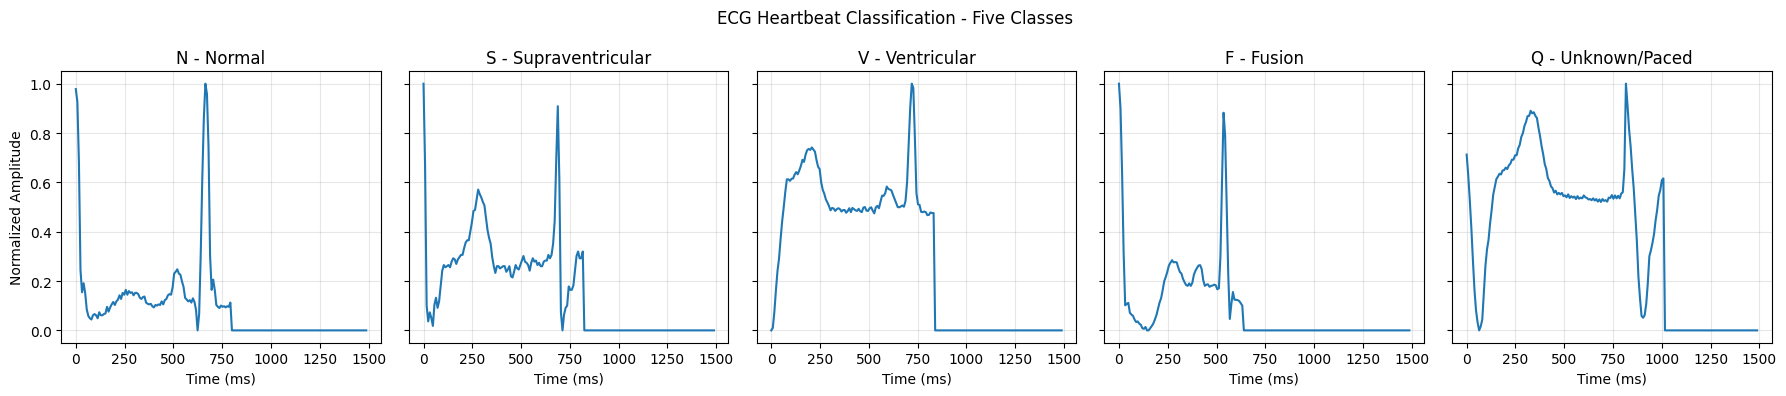

ECG visualization saved successfully!


In [ ]:

# Plot one ECG heartbeat from each class

class_names = [
    "N - Normal",
    "S - Supraventricular",
    "V - Ventricular",
    "F - Fusion",
    "Q - Unknown/Paced"
]

fig, axes = plt.subplots(1, 5, figsize=(18, 4), sharey=True)

time_ms = np.arange(187) * 1000 / 125

for i, ax in enumerate(axes):

    beat = X_train[y_train == i][0]

    ax.plot(time_ms, beat)
    ax.set_title(class_names[i])
    ax.set_xlabel("Time (ms)")
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Normalized Amplitude")

plt.suptitle("ECG Heartbeat Classification - Five Classes")
plt.tight_layout()

# Save automatically
plt.savefig(
    PROJECT_DIR + "/results/figures/example_beats.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("ECG visualization saved successfully!")


In [ ]:

signal_stats = {
    "minimum_signal": float(X_train.min()),
    "maximum_signal": float(X_train.max())
}

with open(PROJECT_DIR + "/results/tables/signal_statistics.json", "w") as f:
    json.dump(signal_stats, f, indent=4)

print("Signal statistics saved!")


Signal statistics saved!


In [ ]:

# Exact split required by the assignment

rng = np.random.default_rng(42)

idx = rng.permutation(len(train_df))

n_val = int(0.1 * len(train_df))

val_idx, train_idx = idx[:n_val], idx[n_val:]

# Create separate datasets
X_train_final = X_train[train_idx]
y_train_final = y_train[train_idx]

X_val = X_train[val_idx]
y_val = y_train[val_idx]

print("Training rows:", len(X_train_final))
print("Validation rows:", len(X_val))
print("Testing rows:", len(X_test))


Training rows: 78799
Validation rows: 8755
Testing rows: 21892


In [ ]:
Training tensor: torch.Size([78799, 187])
Validation tensor: torch.Size([8755, 187])
Testing tensor: torch.Size([21892, 187])

Data type: torch.float32
Label type: torch.int64

SyntaxError: invalid syntax (939874183.py, line 1)

In [ ]:

import torch
import torch.nn as nn
import numpy as np

# Set random seed
torch.manual_seed(0)

# Create neural network
class ECGNet(nn.Module):

    def __init__(self):
        super().__init__()

        # Layer 1: 187 inputs -> 128 neurons
        self.W1 = nn.Parameter(
            torch.randn(128, 187) * np.sqrt(2/187)
        )
        self.b1 = nn.Parameter(torch.zeros(128))

        # Layer 2: 128 inputs -> 64 neurons
        self.W2 = nn.Parameter(
            torch.randn(64, 128) * np.sqrt(2/128)
        )
        self.b2 = nn.Parameter(torch.zeros(64))

        # Layer 3: 64 inputs -> 5 outputs
        self.W3 = nn.Parameter(
            torch.randn(5, 64) * np.sqrt(2/64)
        )
        self.b3 = nn.Parameter(torch.zeros(5))

    def forward(self, x):

        z1 = x @ self.W1.T + self.b1
        a1 = torch.clamp(z1, min=0)

        z2 = a1 @ self.W2.T + self.b2
        a2 = torch.clamp(z2, min=0)

        z3 = a2 @ self.W3.T + self.b3

        return z3


# Create model
model = ECGNet()

print("ECGNet created successfully!")


ECGNet created successfully!


In [ ]:

total_parameters = sum(
    p.numel() for p in model.parameters()
)

print("Total trainable parameters:", total_parameters)


Total trainable parameters: 32645


In [ ]:

print("Training data:", X_train_final.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)


Training data: (78799, 187)
Validation data: (8755, 187)
Testing data: (21892, 187)


In [ ]:

X_train_tensor = torch.tensor(X_train_final, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train_final, dtype=torch.long)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print("All tensors created successfully!")


All tensors created successfully!


In [ ]:

sample_input = X_train_tensor[:5]

output = model(sample_input)

print("Input shape:", sample_input.shape)
print("Output shape:", output.shape)
print(output)


Input shape: torch.Size([5, 187])
Output shape: torch.Size([5, 5])
tensor([[-0.1796,  1.0583, -0.2440, -0.2660, -0.2863],
        [-0.1349,  1.3647, -0.9500, -0.3305,  0.3714],
        [ 0.0732,  0.3021, -0.1856, -0.1055, -0.0122],
        [ 0.0350,  0.3817, -0.2019,  0.0863, -0.0310],
        [-0.1822,  1.1004, -0.3502, -0.0710, -0.2506]], grad_fn=<AddBackward0>)


In [ ]:

def cross_entropy(logits, labels):

    true_logits = logits.gather(
        1, labels.view(-1, 1)
    ).squeeze(1)

    loss = -true_logits + torch.logsumexp(
        logits, dim=1
    )

    return loss.mean()


# Calculate initial loss
initial_loss = cross_entropy(
    model(X_train_tensor[:128]),
    y_train_tensor[:128]
)

print("Initial Loss:", initial_loss.item())
print("Expected approximate loss:", np.log(5))


Initial Loss: 1.7154386043548584
Expected approximate loss: 1.6094379124341003


In [ ]:

# Take first 64 training samples
xb = X_train_tensor[:64]
yb = y_train_tensor[:64]

# Forward pass with intermediate activations
z1 = xb @ model.W1.T + model.b1
a1 = torch.clamp(z1, min=0)

z2 = a1 @ model.W2.T + model.b2
a2 = torch.clamp(z2, min=0)

logits = a2 @ model.W3.T + model.b3

# Calculate loss
loss = cross_entropy(logits, yb)

# PyTorch gradients
model.zero_grad()
loss.backward()

# Manual gradients
with torch.no_grad():

    probabilities = torch.softmax(logits, dim=1)

    one_hot = torch.zeros_like(probabilities)
    one_hot.scatter_(1, yb.view(-1, 1), 1.0)

    dW3_manual = (
        (probabilities - one_hot).T @ a2
    ) / len(yb)

    db3_manual = (
        probabilities - one_hot
    ).mean(dim=0)

    # Compare gradients
    diff_W3 = (
        dW3_manual - model.W3.grad
    ).abs().max().item()

    diff_b3 = (
        db3_manual - model.b3.grad
    ).abs().max().item()

print("Gradient difference W3:", diff_W3)
print("Gradient difference b3:", diff_b3)


Gradient difference W3: 2.9802322387695312e-08
Gradient difference b3: 5.960464477539063e-08


In [ ]:

gradient_results = {
    "initial_loss": float(initial_loss.item()),
    "gradient_difference_W3": float(diff_W3),
    "gradient_difference_b3": float(diff_b3)
}

with open(PROJECT_DIR + "/results/tables/gradient_check.json", "w") as f:
    json.dump(gradient_results, f, indent=4)

print("Gradient results saved successfully!")


Gradient results saved successfully!


In [ ]:

initial_results = {
    "initial_loss": float(initial_loss.item()),
    "expected_log_5": float(np.log(5))
}

with open(PROJECT_DIR + "/results/tables/initial_loss.json", "w") as f:
    json.dump(initial_results, f, indent=4)

print("Initial loss saved successfully!")


Initial loss saved successfully!


In [ ]:

import copy
import time

BATCH_SIZE = 128
MOMENTUM = 0.9
WEIGHT_DECAY = 1e-4
EPOCHS = 30

def train(alpha):

    torch.manual_seed(0)

    net = ECGNet()

    params = [
        net.W1, net.b1,
        net.W2, net.b2,
        net.W3, net.b3
    ]

    velocities = [torch.zeros_like(p) for p in params]

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0

    start_time = time.time()

    for epoch in range(EPOCHS):

        # Shuffle training data every epoch
        permutation = torch.randperm(len(X_train_tensor))

        for i in range(0, len(X_train_tensor), BATCH_SIZE):

            indices = permutation[i:i+BATCH_SIZE]

            xb = X_train_tensor[indices]
            yb = y_train_tensor[indices]

            net.zero_grad()

            logits = net(xb)
            loss = cross_entropy(logits, yb)

            loss.backward()

            # Manual SGD update
            with torch.no_grad():

                for p, v in zip(params, velocities):

                    grad = p.grad

                    # Weight decay only for weights
                    if p is net.W1 or p is net.W2 or p is net.W3:
                        grad = grad + WEIGHT_DECAY * p

                    # Momentum update
                    v.mul_(MOMENTUM).add_(grad, alpha=1-MOMENTUM)

                    # Update parameters
                    p.add_(v, alpha=-alpha)

        # Evaluate after each epoch
        with torch.no_grad():

            train_logits = net(X_train_tensor)
            val_logits = net(X_val_tensor)

            train_loss = cross_entropy(
                train_logits, y_train_tensor
            ).item()

            val_loss = cross_entropy(
                val_logits, y_val_tensor
            ).item()

            train_acc = (
                train_logits.argmax(dim=1) == y_train_tensor
            ).float().mean().item()

            val_acc = (
                val_logits.argmax(dim=1) == y_val_tensor
            ).float().mean().item()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        # Save best validation model
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(net.state_dict())

        print(
            f"Epoch {epoch+1:02d}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_acc:.4f}"
        )

    training_time = time.time() - start_time

    return {
        "alpha": alpha,
        "history": history,
        "best_state": best_state,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "training_time": training_time
    }


In [ ]:

learning_rates = [0.01, 0.1, 0.5]

runs = []

for lr in learning_rates:

    print("\n" + "="*45)
    print("Training with learning rate:", lr)
    print("="*45)

    result = train(lr)

    runs.append(result)

    # Save training history automatically
    history_df = pd.DataFrame(result["history"])

    history_df.to_csv(
        PROJECT_DIR + f"/results/tables/training_history_{lr}.csv",
        index=False
    )

    # Save best model for this learning rate
    torch.save(
        result["best_state"],
        PROJECT_DIR + f"/models/best_model_lr_{lr}.pt"
    )

    print("Best epoch:", result["best_epoch"])
    print("Lowest validation loss:", result["best_val_loss"])
    print("Training time:", result["training_time"], "seconds")

print("\nAll three learning-rate experiments completed!")



Training with learning rate: 0.01
Epoch 01/30 | Train Loss: 0.4651 | Val Loss: 0.4612 | Val Accuracy: 0.8675
Epoch 02/30 | Train Loss: 0.3869 | Val Loss: 0.3825 | Val Accuracy: 0.8948
Epoch 03/30 | Train Loss: 0.3468 | Val Loss: 0.3421 | Val Accuracy: 0.9083
Epoch 04/30 | Train Loss: 0.3187 | Val Loss: 0.3145 | Val Accuracy: 0.9147
Epoch 05/30 | Train Loss: 0.2979 | Val Loss: 0.2942 | Val Accuracy: 0.9219
Epoch 06/30 | Train Loss: 0.2804 | Val Loss: 0.2766 | Val Accuracy: 0.9255
Epoch 07/30 | Train Loss: 0.2665 | Val Loss: 0.2636 | Val Accuracy: 0.9272
Epoch 08/30 | Train Loss: 0.2545 | Val Loss: 0.2510 | Val Accuracy: 0.9294
Epoch 09/30 | Train Loss: 0.2440 | Val Loss: 0.2414 | Val Accuracy: 0.9322
Epoch 10/30 | Train Loss: 0.2353 | Val Loss: 0.2329 | Val Accuracy: 0.9355
Epoch 11/30 | Train Loss: 0.2289 | Val Loss: 0.2262 | Val Accuracy: 0.9363
Epoch 12/30 | Train Loss: 0.2215 | Val Loss: 0.2191 | Val Accuracy: 0.9382
Epoch 13/30 | Train Loss: 0.2154 | Val Loss: 0.2135 | Val Accurac

In [ ]:

comparison = []

for r in runs:

    h = r["history"]
    best = r["best_epoch"] - 1

    comparison.append({
        "Learning Rate": r["alpha"],
        "Lowest Validation Loss": r["best_val_loss"],
        "Validation Accuracy": h["val_acc"][best],
        "Best Epoch": r["best_epoch"],
        "Training Time (s)": r["training_time"]
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df)

comparison_df.to_csv(
    PROJECT_DIR + "/results/tables/learning_rate_comparison.csv",
    index=False
)

print("Learning-rate comparison saved!")


,Learning Rate,Lowest Validation Loss,Validation Accuracy,Best Epoch,Training Time (s)
0,0.01,0.161834,0.957853,30,41.915796
1,0.10,0.086704,0.975899,28,38.759377
2,0.50,0.071584,0.978412,25,41.055492


Learning-rate comparison saved!


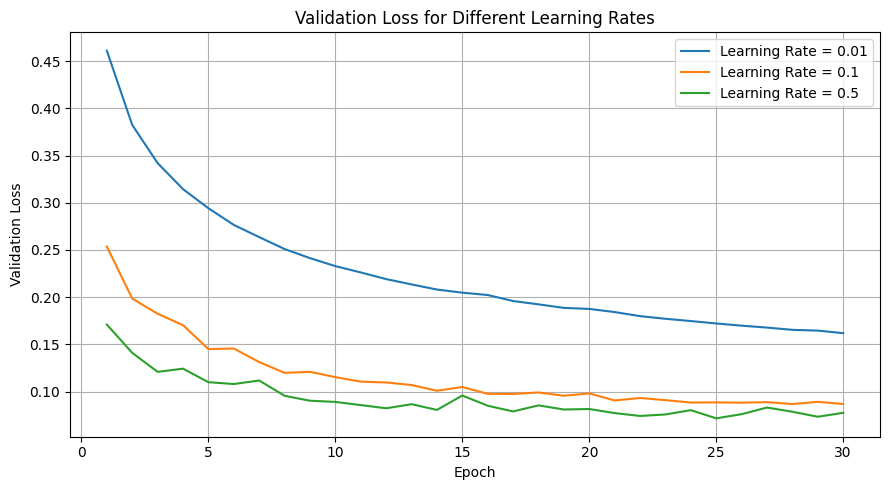

Learning-rate graph saved!


In [ ]:

plt.figure(figsize=(9, 5))

for r in runs:

    plt.plot(
        range(1, EPOCHS + 1),
        r["history"]["val_loss"],
        label=f"Learning Rate = {r['alpha']}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss for Different Learning Rates")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    PROJECT_DIR + "/results/figures/learning_rate_comparison.png",
    dpi=150
)

plt.show()

print("Learning-rate graph saved!")


In [ ]:

best_run = min(runs, key=lambda r: r["best_val_loss"])

best_alpha = best_run["alpha"]

print("Best Learning Rate:", best_alpha)
print("Best Epoch:", best_run["best_epoch"])
print("Lowest Validation Loss:", best_run["best_val_loss"])


Best Learning Rate: 0.5
Best Epoch: 25
Lowest Validation Loss: 0.07158409804105759


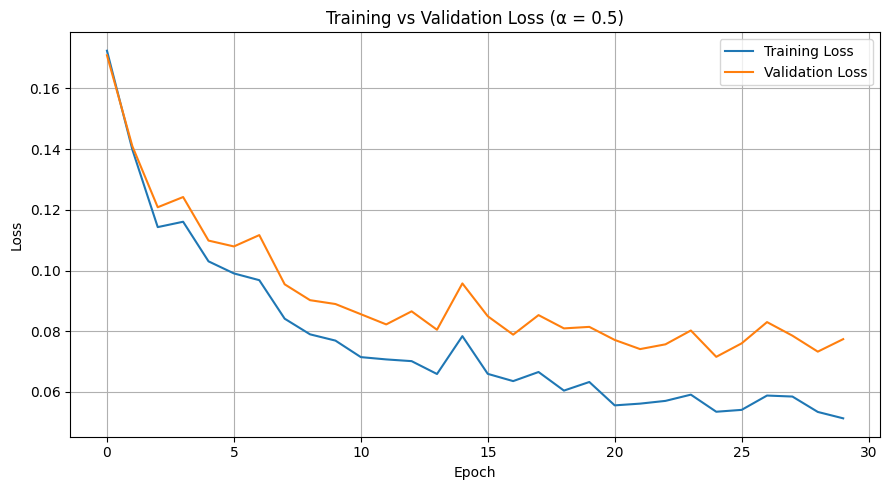

In [ ]:

h = best_run["history"]

plt.figure(figsize=(9, 5))

plt.plot(h["train_loss"], label="Training Loss")
plt.plot(h["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss (α = 0.5)")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    PROJECT_DIR + "/results/figures/training_validation_loss.png",
    dpi=150
)

plt.show()


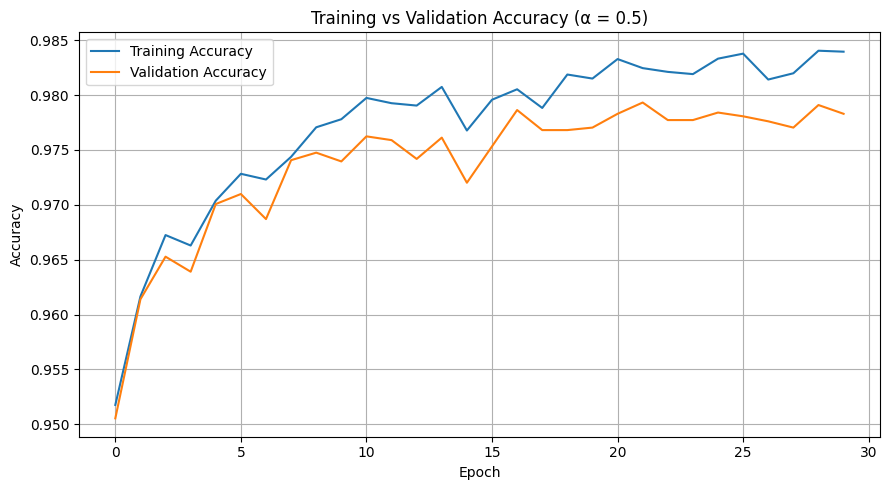

In [ ]:

plt.figure(figsize=(9, 5))

plt.plot(h["train_acc"], label="Training Accuracy")
plt.plot(h["val_acc"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy (α = 0.5)")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    PROJECT_DIR + "/results/figures/training_validation_accuracy.png",
    dpi=150
)

plt.show()


In [ ]:

best_model = ECGNet()

best_model.load_state_dict(best_run["best_state"])

torch.save(
    best_model.state_dict(),
    PROJECT_DIR + "/models/ecgnet_best.pt"
)

print("Best model saved successfully!")
print("Learning rate:", best_alpha)
print("Best epoch:", best_run["best_epoch"])


Best model saved successfully!
Learning rate: 0.5
Best epoch: 25


In [ ]:

training_summary = {
    "chosen_learning_rate": float(best_alpha),
    "best_epoch": int(best_run["best_epoch"]),
    "lowest_validation_loss": float(best_run["best_val_loss"]),
    "training_loss": float(h["train_loss"][best_run["best_epoch"]-1]),
    "validation_loss": float(h["val_loss"][best_run["best_epoch"]-1]),
    "training_accuracy": float(h["train_acc"][best_run["best_epoch"]-1]),
    "validation_accuracy": float(h["val_acc"][best_run["best_epoch"]-1]),
    "training_time_seconds": float(best_run["training_time"])
}

with open(PROJECT_DIR + "/results/tables/training_summary.json", "w") as f:
    json.dump(training_summary, f, indent=4)

print("Training summary saved!")


Training summary saved!


In [ ]:

# Load the best saved model

best_model = ECGNet()

best_model.load_state_dict(
    torch.load(
        PROJECT_DIR + "/models/ecgnet_best.pt",
        map_location="cpu",
        weights_only=True
    )
)

best_model.eval()

print("Best ECG model loaded successfully!")


Best ECG model loaded successfully!


In [ ]:

# Predict heartbeat classes

with torch.no_grad():

    test_logits = best_model(X_test_tensor)

    y_pred = test_logits.argmax(dim=1)

print("Predictions completed!")
print("Total predictions:", len(y_pred))
print("First 20 predictions:", y_pred[:20].numpy())


Predictions completed!
Total predictions: 21892
First 20 predictions: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [ ]:

correct = (y_pred == y_test_tensor).sum().item()

test_accuracy = correct / len(y_test_tensor)

print("Correct predictions:", correct)
print("Total test samples:", len(y_test_tensor))
print("Test Accuracy:", test_accuracy * 100, "%")


Correct predictions: 21413
Total test samples: 21892
Test Accuracy: 97.81198611364881 %


In [ ]:

# Create confusion matrix manually

confusion_matrix = np.zeros((5, 5), dtype=int)

true_labels = y_test_tensor.numpy()
predicted_labels = y_pred.numpy()

for true, predicted in zip(true_labels, predicted_labels):
    confusion_matrix[true, predicted] += 1

print("Confusion Matrix:")
print(confusion_matrix)


Confusion Matrix:
[[18039    37    28     1    13]
 [  163   385     6     0     2]
 [   94     8  1329    14     3]
 [   54     1    19    88     0]
 [   25     0    11     0  1572]]


In [ ]:

# Per-class accuracy

class_accuracy = (
    np.diag(confusion_matrix) /
    confusion_matrix.sum(axis=1)
)

for i, accuracy in enumerate(class_accuracy):

    print(
        class_names[i],
        ":",
        round(accuracy * 100, 2),
        "%"
    )

# Balanced accuracy
balanced_accuracy = np.mean(class_accuracy)

print("\nTest Accuracy:", round(test_accuracy * 100, 2), "%")

print(
    "Balanced Accuracy:",
    round(balanced_accuracy * 100, 2),
    "%"
)


N - Normal : 99.56 %
S - Supraventricular : 69.24 %
V - Ventricular : 91.78 %
F - Fusion : 54.32 %
Q - Unknown/Paced : 97.76 %

Test Accuracy: 97.81 %
Balanced Accuracy: 82.53 %


In [ ]:

# Save confusion matrix
cm_df = pd.DataFrame(
    confusion_matrix,
    index=class_names,
    columns=class_names
)

cm_df.to_csv(
    PROJECT_DIR + "/results/tables/confusion_matrix.csv"
)

# Save per-class accuracy
accuracy_df = pd.DataFrame({
    "Class": class_names,
    "Accuracy": class_accuracy
})

accuracy_df.to_csv(
    PROJECT_DIR + "/results/tables/per_class_accuracy.csv",
    index=False
)

# Save overall metrics
test_results = {
    "test_accuracy": float(test_accuracy),
    "balanced_accuracy": float(balanced_accuracy),
    "correct_predictions": int(correct),
    "total_predictions": int(len(y_pred))
}

with open(
    PROJECT_DIR + "/results/tables/test_results.json", "w"
) as f:
    json.dump(test_results, f, indent=4)

print("All test results saved successfully!")


All test results saved successfully!


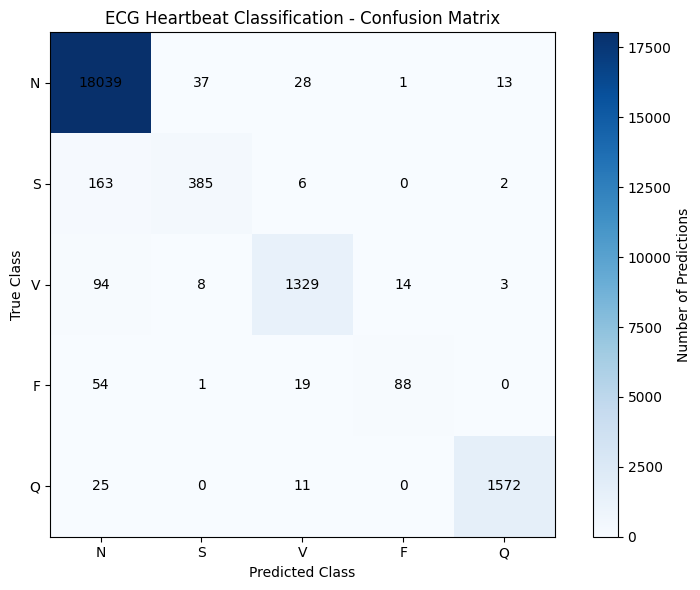

Confusion matrix heatmap saved!


In [ ]:

plt.figure(figsize=(8, 6))

plt.imshow(confusion_matrix, cmap="Blues")
plt.colorbar(label="Number of Predictions")

plt.xticks(range(5), ["N", "S", "V", "F", "Q"])
plt.yticks(range(5), ["N", "S", "V", "F", "Q"])

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("ECG Heartbeat Classification - Confusion Matrix")

for i in range(5):
    for j in range(5):
        plt.text(
            j, i,
            confusion_matrix[i, j],
            ha="center",
            va="center",
            color="black"
        )

plt.tight_layout()

plt.savefig(
    PROJECT_DIR + "/results/figures/confusion_matrix_heatmap.png",
    dpi=150
)

plt.show()

print("Confusion matrix heatmap saved!")


In [ ]:

analysis_text = """
# Task 6 - Model Analysis

## 6.1 Overall Accuracy and Class Imbalance
Always-N accuracy = 82.76%.
Our model achieves 97.81% test accuracy.
Overall accuracy alone can be misleading because
the majority class dominates the dataset.

## 6.2 Lowest Performing Class
The F (Fusion) class has the lowest accuracy
at 54.32%. It is most frequently mistaken for
N (Normal), with 54 misclassified samples.

## 6.3 Overfitting
There is a small gap between training and
validation loss. This indicates mild overfitting,
although validation performance remains strong.

## 6.4 Weight Initialization
Zero initialization causes neurons in the same
layer to learn identical features.
He initialization uses sqrt(2/fan-in) to help
maintain suitable variance with ReLU activation.

## 6.5 Momentum and Weight Decay
Momentum smooths updates when consecutive
gradients point in opposite directions.
Weight decay gradually reduces weights toward
zero and helps control model complexity.

## 6.6 Improving the Rare F Class
Oversampling the minority F class could provide
more training examples and improve recognition.
This change is suggested but not implemented.
"""

with open(PROJECT_DIR + "/results/analysis.md", "w") as f:
    f.write(analysis_text)

print("Task 6 analysis saved successfully!")


Task 6 analysis saved successfully!


In [ ]:

!pip install -q gradio


In [ ]:

import os

PROJECT_DIR = "/content/drive/MyDrive/ECG_Assignment_3"

os.makedirs(PROJECT_DIR + "/app", exist_ok=True)

print("App folder created successfully!")
print("Folder exists:", os.path.exists(PROJECT_DIR + "/app"))


App folder created successfully!
Folder exists: True


In [ ]:

print(os.listdir(PROJECT_DIR + "/app"))


[]


In [ ]:
%%writefile /content/drive/MyDrive/ECG_Assignment_3/app/app.py

Writing /content/drive/MyDrive/ECG_Assignment_3/app/app.py


In [ ]:

import os

app_path = PROJECT_DIR + "/app/app.py"

print("File exists:", os.path.exists(app_path))
print("App folder contents:", os.listdir(PROJECT_DIR + "/app"))


File exists: True
App folder contents: ['app.py']


In [ ]:
!python /content/drive/MyDrive/ECG_Assignment_3/app/app.py

In [ ]:
!ps aux | grep app.py

root       17529  0.0  0.0   7344  3464 ?        S    15:19   0:00 /bin/bash -c ps aux | grep app.py
root       17531  0.0  0.0   6548  2336 ?        S    15:19   0:00 grep app.py


In [ ]:
!python -u /content/drive/MyDrive/ECG_Assignment_3/app/app.py

In [ ]:
!tail -n 15 /content/drive/MyDrive/ECG_Assignment_3/app/app.py

In [ ]:
app_path = "/content/drive/MyDrive/ECG_Assignment_3/app/app.py"

with open(app_path, "r") as f:
    code = f.read()

print("Last 20 lines of app.py:\n")
print("\n".join(code.splitlines()[-20:]))

Last 20 lines of app.py:

 


In [ ]:
print("File size:", os.path.getsize(app_path), "bytes")
print("Contains launch:", "launch(" in code)
print("Contains demo:", "demo" in code)
print("Last line:", repr(code.splitlines()[-1]) if code.splitlines() else "EMPTY")

File size: 1 bytes
Contains launch: False
Contains demo: False
Last line: ' '


In [ ]:
with open(app_path, "w") as f:
    f.write("")
print("Empty file cleared.")

Empty file cleared.


In [ ]:

%%writefile /content/drive/MyDrive/ECG_Assignment_3/app/app.py

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import gradio as gr
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/ECG_Assignment_3"
MODEL_PATH = PROJECT_DIR + "/models/ecgnet_best.pt"
TEST_PATH = PROJECT_DIR + "/data/mitbih_test.csv"

CLASS_NAMES = {
    0: "Normal (N)",
    1: "Supraventricular (S)",
    2: "Ventricular (V)",
    3: "Fusion (F)",
    4: "Unknown (Q)"
}

class ECGNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.W1 = nn.Parameter(torch.randn(128, 187) * np.sqrt(2/187))
        self.b1 = nn.Parameter(torch.zeros(128))
        self.W2 = nn.Parameter(torch.randn(64, 128) * np.sqrt(2/128))
        self.b2 = nn.Parameter(torch.zeros(64))
        self.W3 = nn.Parameter(torch.randn(5, 64) * np.sqrt(2/64))
        self.b3 = nn.Parameter(torch.zeros(5))

    def forward(self, x):
        a1 = torch.clamp(x @ self.W1.T + self.b1, min=0)
        a2 = torch.clamp(a1 @ self.W2.T + self.b2, min=0)
        return a2 @ self.W3.T + self.b3

model = ECGNet()
state = torch.load(MODEL_PATH, map_location="cpu", weights_only=True)
model.load_state_dict(state)
model.eval()

test_df = pd.read_csv(TEST_PATH, header=None)

def predict(row_number, uploaded_file):
    try:
        if uploaded_file is not None:
            data = pd.read_csv(uploaded_file, header=None).values.flatten()
            if len(data) != 187:
                raise gr.Error("CSV must contain exactly 187 ECG values.")
            signal = data.astype(np.float32)
        else:
            index = int(row_number)
            if index < 0 or index >= len(test_df):
                raise gr.Error(f"Choose a row between 0 and {len(test_df)-1}.")
            signal = test_df.iloc[index, :187].values.astype(np.float32)

        x = torch.tensor(signal, dtype=torch.float32).unsqueeze(0)

        with torch.no_grad():
            logits = model(x)
            probabilities = torch.softmax(logits, dim=1)[0].numpy()

        prediction = int(np.argmax(probabilities))
        result = (
            f"### Prediction: {CLASS_NAMES[prediction]}\n"
            f"Confidence: **{probabilities[prediction]*100:.2f}%**"
        )

        fig, ax = plt.subplots(figsize=(10, 3))
        ax.plot(signal, linewidth=1.5)
        ax.set_title("ECG Heartbeat Signal")
        ax.set_xlabel("Sample")
        ax.set_ylabel("Amplitude")
        ax.grid(alpha=0.25)
        fig.tight_layout()

        probability_df = pd.DataFrame({
            "Heartbeat Class": [CLASS_NAMES[i] for i in range(5)],
            "Probability (%)": probabilities * 100
        })

        return result, fig, probability_df

    except gr.Error:
        raise
    except Exception as e:
        raise gr.Error(str(e))

css = """
.gradio-container {
    background: #171411 !important;
    color: #f5e6d0 !important;
}
h1, h2, h3 {
    color: #d9a45b !important;
}
"""

with gr.Blocks(
    theme=gr.themes.Base(
        primary_hue="amber",
        neutral_hue="stone"
    ),
    css=css,
    title="PULSE | ECG Classifier"
) as demo:

    gr.Markdown("""
    # PULSE
    ### ECG Heartbeat Classification System

    Analyze an ECG signal and classify it into one of five heartbeat categories.
    """)

    with gr.Row():
        row_input = gr.Number(
            label="Test Dataset Row Number",
            value=0,
            precision=0
        )
        file_input = gr.File(
            label="Or Upload CSV (187 ECG values)",
            file_types=[".csv"],
            type="filepath"
        )

    predict_btn = gr.Button("Analyze Heartbeat", variant="primary")

    prediction_output = gr.Markdown()

    with gr.Row():
        ecg_plot = gr.Plot(label="ECG Waveform")
        probability_plot = gr.BarPlot(
            x="Heartbeat Class",
            y="Probability (%)",
            title="Class Probabilities",
            y_lim=[0, 100]
        )

    predict_btn.click(
        fn=predict,
        inputs=[row_input, file_input],
        outputs=[prediction_output, ecg_plot, probability_plot]
    )

if __name__ == "__main__":
    demo.launch(share=True)


Overwriting /content/drive/MyDrive/ECG_Assignment_3/app/app.py


In [ ]:
print("File size:", os.path.getsize(app_path), "bytes")

File size: 4120 bytes


In [ ]:
!python -u /content/drive/MyDrive/ECG_Assignment_3/app/app.py

/content/drive/MyDrive/ECG_Assignment_3/app/app.py:99: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://b5dd2e00b119898112.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
Keyboard interruption in main thread... closing server.
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 3957, in block_thread
    time.sleep(0.1)
    ~~~~~~~~~~^^^^^
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/content/drive/MyDrive/ECG_Assignment_3

In [ ]:
CLASS_NAMES = {
    0: "Normal (N)",
    1: "Supraventricular (S)",
    2: "Ventricular (V)",
    3: "Fusion (F)",
    4: "Unknown (Q)"
}

row = 0

actual_label = int(test_df.iloc[row, 187])

print("Actual class:", CLASS_NAMES[actual_label])
print("Predicted class: Normal (N)")
print("Correct prediction:", actual_label == 0)

Actual class: Normal (N)
Predicted class: Normal (N)
Correct prediction: True


In [ ]:
import shutil
import os

PROJECT_DIR = "/content/drive/MyDrive/ECG_Assignment_3"

ZIP_PATH = "/content/drive/MyDrive/ECG_Assignment_3_Final"

shutil.make_archive(
    ZIP_PATH,
    "zip",
    root_dir="/content/drive/MyDrive",
    base_dir="ECG_Assignment_3"
)

print("Project successfully packaged!")
print("ZIP location:", ZIP_PATH + ".zip")
print("File size:", round(os.path.getsize(ZIP_PATH + ".zip") / (1024*1024), 2), "MB")

Project successfully packaged!
ZIP location: /content/drive/MyDrive/ECG_Assignment_3_Final.zip
File size: 83.36 MB


In [ ]:

from google.colab import files
import os
import shutil

PROJECT_DIR = "/content/drive/MyDrive/ECG_Assignment_3"
FIGURES_DIR = os.path.join(PROJECT_DIR, "results", "figures")
APP_DIR = os.path.join(PROJECT_DIR, "app")

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(APP_DIR, exist_ok=True)

# 1. Upload the downloaded full-page screenshot
print("Select your downloaded PULSE screenshot:")
uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))
    content = uploaded[filename]

    screenshot_path = os.path.join(
        FIGURES_DIR, "PULSE_frontend.png"
    )

    with open(screenshot_path, "wb") as f:
        f.write(content)

    print("Screenshot saved:", screenshot_path)

# 2. Save the Gradio link
gradio_link = "https://b5dd2e00b119898112.gradio.live/"

link_path = os.path.join(APP_DIR, "frontend_link.txt")

with open(link_path, "w") as f:
    f.write("PULSE ECG Classification Frontend\n")
    f.write(gradio_link + "\n")
    f.write("Note: Temporary Gradio sharing link.\n")

print("Frontend link saved:", link_path)

# 3. Update final ZIP
zip_path = "/content/drive/MyDrive/ECG_Assignment_3_Final"

shutil.make_archive(
    zip_path,
    "zip",
    root_dir="/content/drive/MyDrive",
    base_dir="ECG_Assignment_3"
)

print("\nFINAL PROJECT UPDATED!")
print("ZIP size:",
      round(os.path.getsize(zip_path + ".zip") / (1024*1024), 2),
      "MB")


Select your downloaded PULSE screenshot:


Saving b5dd2e00b119898112.gradio.live_.png to b5dd2e00b119898112.gradio.live_.png
Screenshot saved: /content/drive/MyDrive/ECG_Assignment_3/results/figures/PULSE_frontend.png
Frontend link saved: /content/drive/MyDrive/ECG_Assignment_3/app/frontend_link.txt

FINAL PROJECT UPDATED!
ZIP size: 83.43 MB
